# Water Quality in Africa - Comprehensive Analysis

This notebook provides an in-depth analysis of water quality data across various locations in Africa, including:
- Statistical summaries
- Temporal trends
- Spatial distribution
- Correlations between water quality parameters
- Geographic visualization

In [1]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import folium
from folium.plugins import HeatMap, MarkerCluster
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

# Set style for better visualizations
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 10

## 1. Data Loading and Initial Exploration

In [2]:
# Load the dataset
df = pd.read_csv('water_quality_training_dataset.csv')

# Convert Sample Date to datetime
df['Sample Date'] = pd.to_datetime(df['Sample Date'], format='%d-%m-%Y')

# Extract temporal features
df['Year'] = df['Sample Date'].dt.year
df['Month'] = df['Sample Date'].dt.month
df['Season'] = df['Month'].map({
    12: 'Summer', 1: 'Summer', 2: 'Summer',
    3: 'Autumn', 4: 'Autumn', 5: 'Autumn',
    6: 'Winter', 7: 'Winter', 8: 'Winter',
    9: 'Spring', 10: 'Spring', 11: 'Spring'
})

print(f"Dataset shape: {df.shape}")
print(f"\nDate range: {df['Sample Date'].min()} to {df['Sample Date'].max()}")
print(f"\nUnique sampling locations: {df[['Latitude', 'Longitude']].drop_duplicates().shape[0]}")
df.head(10)

Dataset shape: (9319, 9)

Date range: 2011-01-02 00:00:00 to 2015-12-31 00:00:00

Unique sampling locations: 162


,Latitude,Longitude,Sample Date,Total Alkalinity,Electrical Conductance,Dissolved Reactive Phosphorus,Year,Month,Season
0,-28.760833,17.730278,2011-01-02,128.912,555.0,10.0,2011,1,Summer
1,-26.861111,28.884722,2011-01-03,74.720,162.9,163.0,2011,1,Summer
2,-26.450000,28.085833,2011-01-03,89.254,573.0,80.0,2011,1,Summer
3,-27.671111,27.236944,2011-01-03,82.000,203.6,101.0,2011,1,Summer
4,-27.356667,27.286389,2011-01-03,56.100,145.1,151.0,2011,1,Summer
5,-27.010111,26.698083,2011-01-04,82.200,289.8,192.0,2011,1,Summer
6,-25.127778,27.628889,2011-01-04,125.000,438.0,163.0,2011,1,Summer
7,-25.206390,27.558000,2011-01-04,116.620,568.0,69.0,2011,1,Summer
8,-24.695140,27.409060,2011-01-04,181.831,583.0,158.0,2011,1,Summer
9,-26.984722,26.632278,2011-01-04,196.000,452.0,158.0,2011,1,Summer


In [3]:
# Data types and missing values
print("Data Info:")
print(df.info())
print("\nMissing Values:")
print(df.isnull().sum())
print(f"\nMissing percentage:")
print((df.isnull().sum() / len(df) * 100).round(2))

Data Info:
<class 'pandas.DataFrame'>
RangeIndex: 9319 entries, 0 to 9318
Data columns (total 9 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   Latitude                       9319 non-null   float64       
 1   Longitude                      9319 non-null   float64       
 2   Sample Date                    9319 non-null   datetime64[us]
 3   Total Alkalinity               9319 non-null   float64       
 4   Electrical Conductance         9319 non-null   float64       
 5   Dissolved Reactive Phosphorus  9319 non-null   float64       
 6   Year                           9319 non-null   int32         
 7   Month                          9319 non-null   int32         
 8   Season                         9319 non-null   str           
dtypes: datetime64[us](1), float64(5), int32(2), str(1)
memory usage: 582.6 KB
None

Missing Values:
Latitude                         0
Longitude            

## 2. Descriptive Statistics

In [4]:
# Statistical summary
print("Comprehensive Statistical Summary:")
print("=" * 80)
df[['Latitude', 'Longitude', 'Total Alkalinity', 'Electrical Conductance', 'Dissolved Reactive Phosphorus']].describe()

Comprehensive Statistical Summary:


,Latitude,Longitude,Total Alkalinity,Electrical Conductance,Dissolved Reactive Phosphorus
count,9319.000000,9319.000000,9319.000000,9319.000000,9319.000000
mean,-28.474988,26.868414,119.108208,485.004146,43.525338
std,2.760282,3.535164,74.692591,341.937736,50.980194
min,-34.405833,17.730278,4.800000,15.120000,5.000000
25%,-30.160091,26.126667,55.811000,207.050000,10.000000
50%,-28.058889,27.409060,113.300000,402.000000,20.000000
75%,-26.861111,29.245556,170.230000,693.000000,48.000000
max,-22.225556,32.325000,361.676000,1506.000000,195.000000


In [5]:
# Additional statistics
water_params = ['Total Alkalinity', 'Electrical Conductance', 'Dissolved Reactive Phosphorus']

stats_df = pd.DataFrame({
    'Parameter': water_params,
    'Mean': [df[col].mean() for col in water_params],
    'Median': [df[col].median() for col in water_params],
    'Std Dev': [df[col].std() for col in water_params],
    'Skewness': [df[col].skew() for col in water_params],
    'Kurtosis': [df[col].kurtosis() for col in water_params],
    'CV (%)': [(df[col].std() / df[col].mean() * 100) for col in water_params]
})

print("\nAdvanced Statistics:")
print(stats_df.to_string(index=False))


Advanced Statistics:
                    Parameter       Mean  Median    Std Dev  Skewness  Kurtosis     CV (%)
             Total Alkalinity 119.108208   113.3  74.692591  0.536229 -0.252385  62.709861
       Electrical Conductance 485.004146   402.0 341.937736  0.929458  0.290124  70.502023
Dissolved Reactive Phosphorus  43.525338    20.0  50.980194  1.644685  1.333726 117.127624


## 3. Distribution Analysis

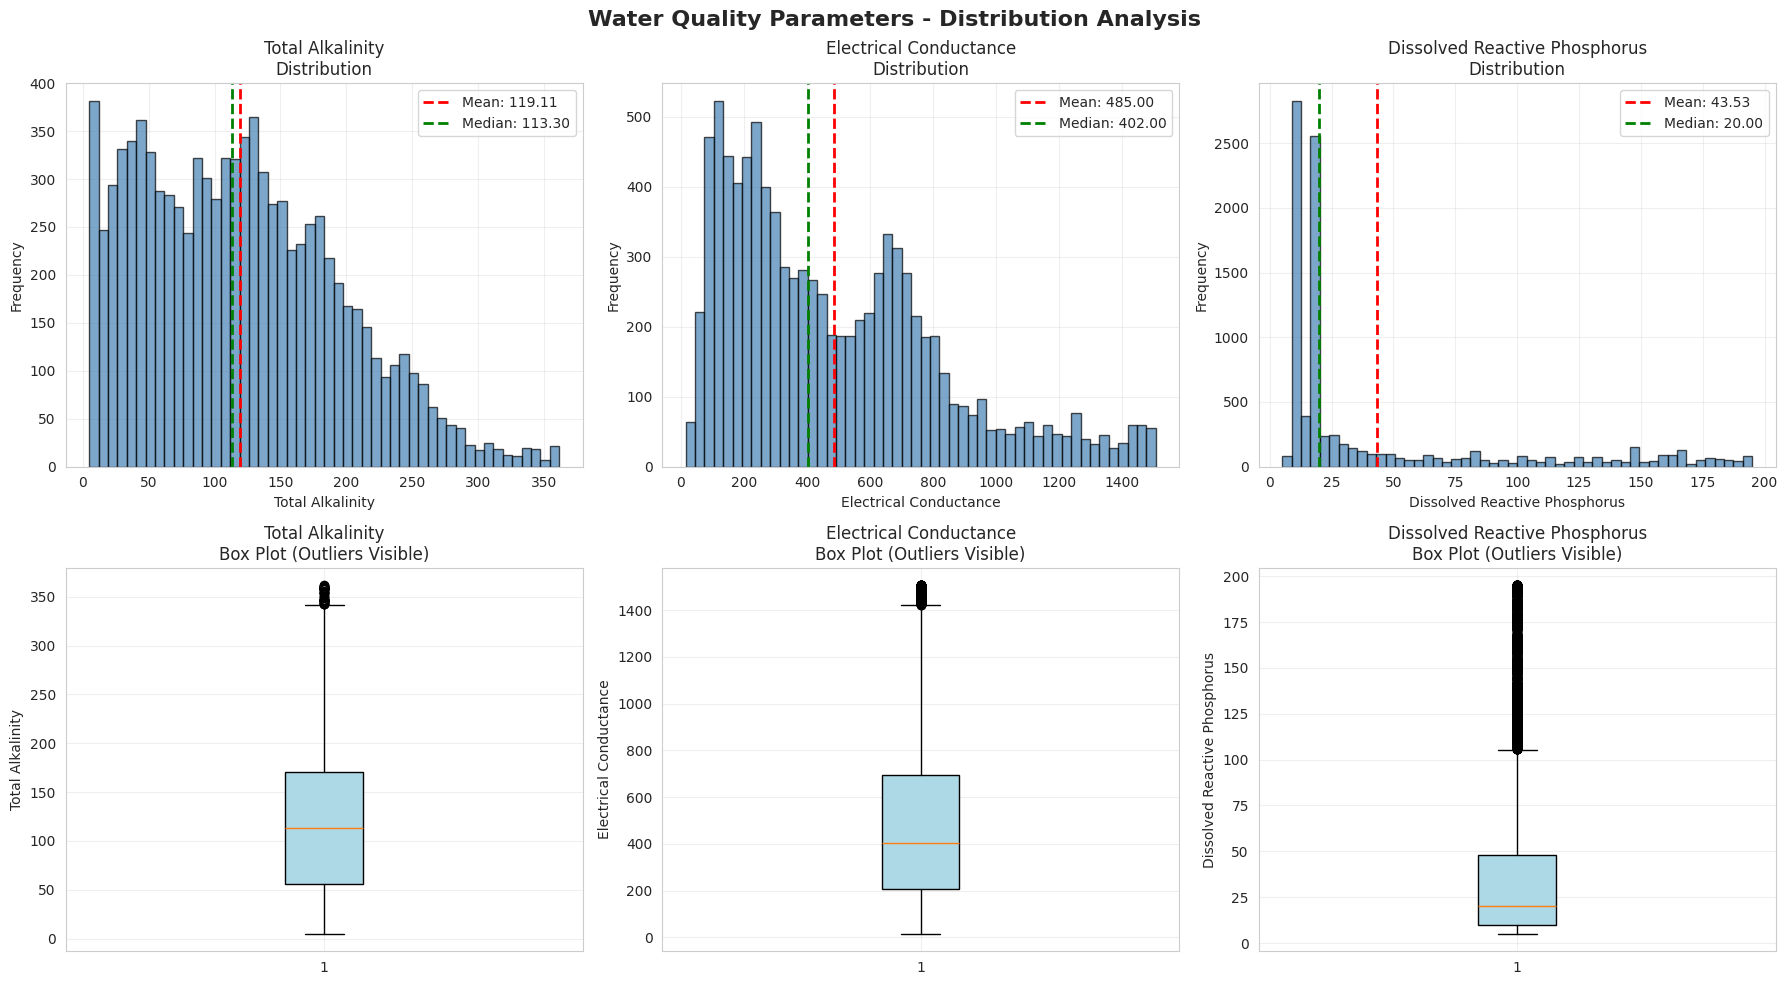

In [6]:
# Distribution plots for all water quality parameters
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('Water Quality Parameters - Distribution Analysis', fontsize=16, fontweight='bold')

for idx, param in enumerate(water_params):
    # Histogram with KDE
    ax1 = axes[0, idx]
    df[param].hist(bins=50, alpha=0.7, color='steelblue', edgecolor='black', ax=ax1)
    ax1.axvline(df[param].mean(), color='red', linestyle='--', linewidth=2, label=f'Mean: {df[param].mean():.2f}')
    ax1.axvline(df[param].median(), color='green', linestyle='--', linewidth=2, label=f'Median: {df[param].median():.2f}')
    ax1.set_xlabel(param)
    ax1.set_ylabel('Frequency')
    ax1.set_title(f'{param}\nDistribution')
    ax1.legend()
    ax1.grid(True, alpha=0.3)
    
    # Box plot
    ax2 = axes[1, idx]
    box = ax2.boxplot(df[param].dropna(), vert=True, patch_artist=True)
    box['boxes'][0].set_facecolor('lightblue')
    box['boxes'][0].set_edgecolor('black')
    ax2.set_ylabel(param)
    ax2.set_title(f'{param}\nBox Plot (Outliers Visible)')
    ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 4. Correlation Analysis

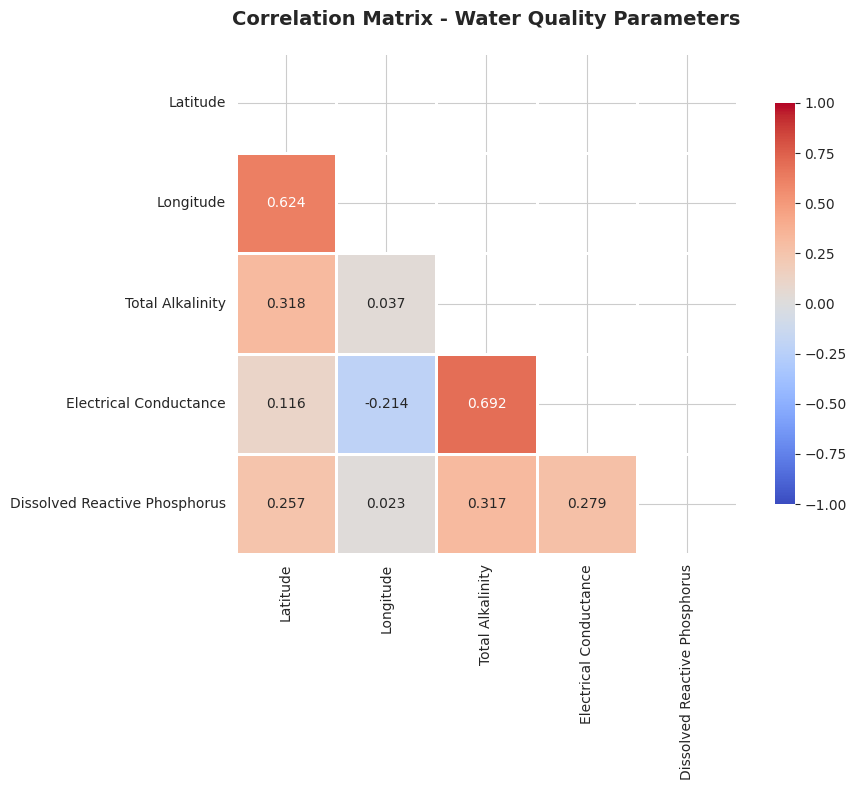


Key Correlations:
Total Alkalinity <-> Electrical Conductance: 0.692
Latitude <-> Longitude: 0.624
Latitude <-> Total Alkalinity: 0.318
Total Alkalinity <-> Dissolved Reactive Phosphorus: 0.317
Electrical Conductance <-> Dissolved Reactive Phosphorus: 0.279
Latitude <-> Dissolved Reactive Phosphorus: 0.257
Longitude <-> Electrical Conductance: -0.214
Latitude <-> Electrical Conductance: 0.116
Longitude <-> Total Alkalinity: 0.037
Longitude <-> Dissolved Reactive Phosphorus: 0.023


In [7]:
# Correlation matrix
correlation_cols = ['Latitude', 'Longitude'] + water_params
corr_matrix = df[correlation_cols].corr()

# Visualize correlation matrix
fig, ax = plt.subplots(figsize=(10, 8))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.3f', cmap='coolwarm', 
            center=0, square=True, linewidths=1, cbar_kws={"shrink": 0.8},
            vmin=-1, vmax=1, ax=ax)
ax.set_title('Correlation Matrix - Water Quality Parameters', fontsize=14, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

print("\nKey Correlations:")
print("=" * 80)
# Get correlations as list and sort by absolute value
corr_pairs = []
for i in range(len(corr_matrix.columns)):
    for j in range(i+1, len(corr_matrix.columns)):
        corr_pairs.append((corr_matrix.columns[i], corr_matrix.columns[j], corr_matrix.iloc[i, j]))

corr_pairs_sorted = sorted(corr_pairs, key=lambda x: abs(x[2]), reverse=True)
for var1, var2, corr in corr_pairs_sorted[:10]:
    print(f"{var1} <-> {var2}: {corr:.3f}")

In [ ]:
# Scatter plots for water quality parameters
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Pairwise Relationships Between Water Quality Parameters', fontsize=14, fontweight='bold')

# Total Alkalinity vs Electrical Conductance
axes[0].scatter(df['Total Alkalinity'], df['Electrical Conductance'], 
                alpha=0.5, s=10, c='steelblue', edgecolors='none')
axes[0].set_xlabel('Total Alkalinity')
axes[0].set_ylabel('Electrical Conductance')
axes[0].set_title(f"Corr: {df['Total Alkalinity'].corr(df['Electrical Conductance']):.3f}")
axes[0].grid(True, alpha=0.3)

# Total Alkalinity vs Dissolved Reactive Phosphorus
axes[1].scatter(df['Total Alkalinity'], df['Dissolved Reactive Phosphorus'], 
                alpha=0.5, s=10, c='coral', edgecolors='none')
axes[1].set_xlabel('Total Alkalinity')
axes[1].set_ylabel('Dissolved Reactive Phosphorus')
axes[1].set_title(f"Corr: {df['Total Alkalinity'].corr(df['Dissolved Reactive Phosphorus']):.3f}")
axes[1].grid(True, alpha=0.3)

# Electrical Conductance vs Dissolved Reactive Phosphorus
axes[2].scatter(df['Electrical Conductance'], df['Dissolved Reactive Phosphorus'], 
                alpha=0.5, s=10, c='seagreen', edgecolors='none')
axes[2].set_xlabel('Electrical Conductance')
axes[2].set_ylabel('Dissolved Reactive Phosphorus')
axes[2].set_title(f"Corr: {df['Electrical Conductance'].corr(df['Dissolved Reactive Phosphorus']):.3f}")
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 5. Temporal Analysis

In [ ]:
# Sampling frequency over time
fig, axes = plt.subplots(2, 1, figsize=(16, 10))

# Samples per year
yearly_counts = df['Year'].value_counts().sort_index()
axes[0].bar(yearly_counts.index, yearly_counts.values, color='steelblue', edgecolor='black', alpha=0.7)
axes[0].set_xlabel('Year')
axes[0].set_ylabel('Number of Samples')
axes[0].set_title('Sampling Frequency by Year', fontsize=12, fontweight='bold')
axes[0].grid(True, alpha=0.3, axis='y')

# Samples per month
monthly_counts = df['Month'].value_counts().sort_index()
month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
axes[1].bar(range(1, 13), [monthly_counts.get(i, 0) for i in range(1, 13)], 
            color='coral', edgecolor='black', alpha=0.7)
axes[1].set_xticks(range(1, 13))
axes[1].set_xticklabels(month_names)
axes[1].set_xlabel('Month')
axes[1].set_ylabel('Number of Samples')
axes[1].set_title('Sampling Frequency by Month (All Years Combined)', fontsize=12, fontweight='bold')
axes[1].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

In [ ]:
# Time series of water quality parameters (monthly averages)
df['Year-Month'] = df['Sample Date'].dt.to_period('M')
monthly_avg = df.groupby('Year-Month')[water_params].mean()

fig, axes = plt.subplots(3, 1, figsize=(16, 12))
fig.suptitle('Temporal Trends - Monthly Averages of Water Quality Parameters', fontsize=14, fontweight='bold')

colors = ['steelblue', 'coral', 'seagreen']
for idx, param in enumerate(water_params):
    axes[idx].plot(monthly_avg.index.astype(str), monthly_avg[param], 
                   marker='o', linewidth=2, markersize=4, color=colors[idx])
    axes[idx].set_ylabel(param, fontsize=11)
    axes[idx].set_title(f'{param} Over Time', fontsize=11, fontweight='bold')
    axes[idx].grid(True, alpha=0.3)
    axes[idx].tick_params(axis='x', rotation=45)
    
    # Add trend line
    x_numeric = np.arange(len(monthly_avg))
    z = np.polyfit(x_numeric, monthly_avg[param], 1)
    p = np.poly1d(z)
    axes[idx].plot(monthly_avg.index.astype(str), p(x_numeric), "--", 
                   color='red', alpha=0.7, linewidth=2, label=f'Trend (slope: {z[0]:.3f})')
    axes[idx].legend()

plt.tight_layout()
plt.show()

In [ ]:
# Seasonal analysis
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Seasonal Variations in Water Quality', fontsize=14, fontweight='bold')

season_order = ['Summer', 'Autumn', 'Winter', 'Spring']
colors_season = ['#FF6B6B', '#FFA500', '#4ECDC4', '#95E1D3']

for idx, param in enumerate(water_params):
    seasonal_data = [df[df['Season'] == season][param].dropna() for season in season_order]
    bp = axes[idx].boxplot(seasonal_data, labels=season_order, patch_artist=True)
    
    for patch, color in zip(bp['boxes'], colors_season):
        patch.set_facecolor(color)
        patch.set_alpha(0.7)
    
    axes[idx].set_ylabel(param)
    axes[idx].set_title(param)
    axes[idx].grid(True, alpha=0.3, axis='y')
    axes[idx].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

# Statistical test for seasonal differences
print("\nKruskal-Wallis Test for Seasonal Differences:")
print("=" * 80)
for param in water_params:
    seasonal_groups = [df[df['Season'] == season][param].dropna() for season in season_order]
    h_stat, p_value = stats.kruskal(*seasonal_groups)
    print(f"{param}:")
    print(f"  H-statistic: {h_stat:.4f}, p-value: {p_value:.4e}")
    if p_value < 0.05:
        print(f"  → Significant seasonal variation detected (p < 0.05)")
    else:
        print(f"  → No significant seasonal variation (p >= 0.05)")
    print()

## 6. Spatial Analysis

In [ ]:
# Geographic distribution of sampling locations
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Scatter plot of all sampling points
axes[0].scatter(df['Longitude'], df['Latitude'], alpha=0.3, s=5, c='steelblue')
axes[0].set_xlabel('Longitude')
axes[0].set_ylabel('Latitude')
axes[0].set_title('Geographic Distribution of All Samples', fontsize=12, fontweight='bold')
axes[0].grid(True, alpha=0.3)

# Unique sampling locations
unique_locations = df[['Latitude', 'Longitude']].drop_duplicates()
axes[1].scatter(unique_locations['Longitude'], unique_locations['Latitude'], 
                alpha=0.6, s=30, c='coral', edgecolors='black', linewidth=0.5)
axes[1].set_xlabel('Longitude')
axes[1].set_ylabel('Latitude')
axes[1].set_title(f'Unique Sampling Locations (n={len(unique_locations)})', fontsize=12, fontweight='bold')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"\nGeographic Extent:")
print(f"Latitude range: {df['Latitude'].min():.4f}° to {df['Latitude'].max():.4f}°")
print(f"Longitude range: {df['Longitude'].min():.4f}° to {df['Longitude'].max():.4f}°")

In [ ]:
# Spatial patterns - average water quality by location
location_stats = df.groupby(['Latitude', 'Longitude'])[water_params].agg(['mean', 'std', 'count'])
location_stats.columns = ['_'.join(col).strip() for col in location_stats.columns.values]
location_stats = location_stats.reset_index()

print(f"Location-based Statistics Summary:")
print(f"Total unique locations: {len(location_stats)}")
print(f"\nSampling frequency per location:")
print(f"  Mean: {location_stats['Total Alkalinity_count'].mean():.1f} samples")
print(f"  Median: {location_stats['Total Alkalinity_count'].median():.1f} samples")
print(f"  Min: {location_stats['Total Alkalinity_count'].min():.0f} samples")
print(f"  Max: {location_stats['Total Alkalinity_count'].max():.0f} samples")

# Visualize spatial patterns
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Average Water Quality Parameters by Location', fontsize=14, fontweight='bold')

params_plot = [
    ('Total Alkalinity_mean', 'Total Alkalinity (Mean)'),
    ('Electrical Conductance_mean', 'Electrical Conductance (Mean)'),
    ('Dissolved Reactive Phosphorus_mean', 'Dissolved Reactive Phosphorus (Mean)')
]

for idx, (col, title) in enumerate(params_plot):
    scatter = axes[idx].scatter(location_stats['Longitude'], location_stats['Latitude'],
                                c=location_stats[col], s=50, cmap='viridis', 
                                alpha=0.7, edgecolors='black', linewidth=0.5)
    axes[idx].set_xlabel('Longitude')
    axes[idx].set_ylabel('Latitude')
    axes[idx].set_title(title)
    axes[idx].grid(True, alpha=0.3)
    plt.colorbar(scatter, ax=axes[idx])

plt.tight_layout()
plt.show()

## 7. Interactive Map Visualization

In [ ]:
# Create base map centered on the mean location
center_lat = df['Latitude'].mean()
center_lon = df['Longitude'].mean()

# Create map with multiple layers
m = folium.Map(
    location=[center_lat, center_lon],
    zoom_start=6,
    tiles='OpenStreetMap'
)

# Add alternative tile layers
folium.TileLayer('Stamen Terrain').add_to(m)
folium.TileLayer('Stamen Toner').add_to(m)
folium.TileLayer('CartoDB positron').add_to(m)

# Create feature groups for different visualizations
marker_cluster = MarkerCluster(name='Sampling Locations (Clustered)').add_to(m)
heat_map_group = folium.FeatureGroup(name='Sample Density Heatmap', show=False)

# Add markers with detailed popups for each unique location
for idx, row in location_stats.iterrows():
    popup_html = f"""
    <div style="font-family: Arial; font-size: 12px; width: 250px;">
        <b>Location:</b> ({row['Latitude']:.4f}, {row['Longitude']:.4f})<br>
        <b>Samples:</b> {int(row['Total Alkalinity_count'])}<br>
        <hr style="margin: 5px 0;">
        <b>Total Alkalinity:</b><br>
        &nbsp;&nbsp;Mean: {row['Total Alkalinity_mean']:.2f}<br>
        &nbsp;&nbsp;Std: {row['Total Alkalinity_std']:.2f}<br>
        <b>Electrical Conductance:</b><br>
        &nbsp;&nbsp;Mean: {row['Electrical Conductance_mean']:.2f}<br>
        &nbsp;&nbsp;Std: {row['Electrical Conductance_std']:.2f}<br>
        <b>Dissolved Reactive Phosphorus:</b><br>
        &nbsp;&nbsp;Mean: {row['Dissolved Reactive Phosphorus_mean']:.2f}<br>
        &nbsp;&nbsp;Std: {row['Dissolved Reactive Phosphorus_std']:.2f}<br>
    </div>
    """
    
    # Color code by electrical conductance (common water quality indicator)
    conductance = row['Electrical Conductance_mean']
    if conductance < 200:
        color = 'green'
    elif conductance < 500:
        color = 'orange'
    else:
        color = 'red'
    
    folium.CircleMarker(
        location=[row['Latitude'], row['Longitude']],
        radius=5,
        popup=folium.Popup(popup_html, max_width=300),
        color=color,
        fill=True,
        fillColor=color,
        fillOpacity=0.7,
        weight=2
    ).add_to(marker_cluster)

# Add heatmap for sample density
heat_data = [[row['Latitude'], row['Longitude'], row['Total Alkalinity_count']] 
             for idx, row in location_stats.iterrows()]
HeatMap(heat_data, name='Sample Density', radius=15, blur=25, max_zoom=10).add_to(heat_map_group)
heat_map_group.add_to(m)

# Add layer control
folium.LayerControl(position='topright', collapsed=False).add_to(m)

# Add legend
legend_html = '''
<div style="position: fixed; 
            bottom: 50px; right: 50px; width: 220px; height: 120px; 
            background-color: white; border:2px solid grey; z-index:9999; 
            font-size:14px; padding: 10px;">
    <b>Electrical Conductance</b><br>
    <i style="background: green; width: 20px; height: 10px; display: inline-block;"></i> Low (&lt;200)<br>
    <i style="background: orange; width: 20px; height: 10px; display: inline-block;"></i> Medium (200-500)<br>
    <i style="background: red; width: 20px; height: 10px; display: inline-block;"></i> High (&gt;500)
</div>
'''
m.get_root().html.add_child(folium.Element(legend_html))

# Save map
m.save('water_quality_map.html')
print("Interactive map saved as 'water_quality_map.html'")
print("\nMap Features:")
print("- Multiple base map layers (OpenStreetMap, Terrain, Toner, etc.)")
print("- Clustered markers for sampling locations")
print("- Color-coded markers by electrical conductance levels")
print("- Detailed popups with statistics for each location")
print("- Heatmap layer showing sample density")
print("- Layer control for toggling visualizations")

# Display map in notebook
m

## 8. Advanced Insights

In [ ]:
# Identify extreme locations
print("LOCATIONS WITH EXTREME VALUES")
print("=" * 80)

for param in water_params:
    col_mean = f"{param}_mean"
    
    # Highest
    highest = location_stats.nlargest(3, col_mean)[['Latitude', 'Longitude', col_mean]]
    print(f"\n{param} - TOP 3 HIGHEST:")
    for idx, row in highest.iterrows():
        print(f"  Location ({row['Latitude']:.4f}, {row['Longitude']:.4f}): {row[col_mean]:.2f}")
    
    # Lowest
    lowest = location_stats.nsmallest(3, col_mean)[['Latitude', 'Longitude', col_mean]]
    print(f"\n{param} - TOP 3 LOWEST:")
    for idx, row in lowest.iterrows():
        print(f"  Location ({row['Latitude']:.4f}, {row['Longitude']:.4f}): {row[col_mean]:.2f}")

In [ ]:
# Temporal stability analysis - locations with high variability
print("\nLOCATIONS WITH HIGHEST VARIABILITY")
print("=" * 80)

for param in water_params:
    col_std = f"{param}_std"
    col_count = f"{param}_count"
    
    # Filter locations with sufficient samples (>5)
    filtered = location_stats[location_stats[col_count] > 5]
    
    if len(filtered) > 0:
        highest_var = filtered.nlargest(3, col_std)[['Latitude', 'Longitude', col_std, col_count]]
        print(f"\n{param} - TOP 3 MOST VARIABLE (with >5 samples):")
        for idx, row in highest_var.iterrows():
            print(f"  Location ({row['Latitude']:.4f}, {row['Longitude']:.4f}):")
            print(f"    Std Dev: {row[col_std]:.2f}, Samples: {int(row[col_count])}")

In [ ]:
# Regional analysis - divide into regions
# Define regions based on latitude (rough approximation for South Africa)
def classify_region(lat):
    if lat > -26:
        return 'Northern Region'
    elif lat > -30:
        return 'Central Region'
    else:
        return 'Southern Region'

df['Region'] = df['Latitude'].apply(classify_region)

# Regional statistics
regional_stats = df.groupby('Region')[water_params].agg(['mean', 'std', 'median', 'count'])

print("\nREGIONAL COMPARISON")
print("=" * 80)
for param in water_params:
    print(f"\n{param}:")
    print(regional_stats[param].to_string())
    
    # Statistical test
    groups = [df[df['Region'] == region][param].dropna() for region in df['Region'].unique()]
    h_stat, p_value = stats.kruskal(*groups)
    print(f"\n  Kruskal-Wallis test: H={h_stat:.4f}, p={p_value:.4e}")
    if p_value < 0.05:
        print(f"  → Significant regional differences detected")
    else:
        print(f"  → No significant regional differences")

In [ ]:
# Regional comparison visualization
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Regional Comparison of Water Quality Parameters', fontsize=14, fontweight='bold')

regions = sorted(df['Region'].unique())
colors_region = ['#E74C3C', '#3498DB', '#2ECC71']

for idx, param in enumerate(water_params):
    regional_data = [df[df['Region'] == region][param].dropna() for region in regions]
    bp = axes[idx].boxplot(regional_data, labels=regions, patch_artist=True)
    
    for patch, color in zip(bp['boxes'], colors_region):
        patch.set_facecolor(color)
        patch.set_alpha(0.7)
    
    axes[idx].set_ylabel(param)
    axes[idx].set_title(param)
    axes[idx].grid(True, alpha=0.3, axis='y')
    axes[idx].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

## 9. Key Findings Summary

In [ ]:
print("\n" + "="*80)
print("KEY FINDINGS - WATER QUALITY IN AFRICA")
print("="*80)

print(f"\n1. DATASET OVERVIEW:")
print(f"   - Total samples: {len(df):,}")
print(f"   - Unique locations: {len(location_stats):,}")
print(f"   - Time period: {df['Sample Date'].min().strftime('%Y-%m-%d')} to {df['Sample Date'].max().strftime('%Y-%m-%d')}")
print(f"   - Geographic extent: {df['Latitude'].min():.2f}° to {df['Latitude'].max():.2f}° (Latitude)")
print(f"                        {df['Longitude'].min():.2f}° to {df['Longitude'].max():.2f}° (Longitude)")

print(f"\n2. WATER QUALITY PARAMETERS:")
for param in water_params:
    print(f"\n   {param}:")
    print(f"     Range: {df[param].min():.2f} - {df[param].max():.2f}")
    print(f"     Mean: {df[param].mean():.2f} ± {df[param].std():.2f}")
    print(f"     Coefficient of Variation: {(df[param].std()/df[param].mean()*100):.1f}%")

print(f"\n3. CORRELATIONS:")
corr_ta_ec = df['Total Alkalinity'].corr(df['Electrical Conductance'])
corr_ta_drp = df['Total Alkalinity'].corr(df['Dissolved Reactive Phosphorus'])
corr_ec_drp = df['Electrical Conductance'].corr(df['Dissolved Reactive Phosphorus'])
print(f"   - Total Alkalinity ↔ Electrical Conductance: {corr_ta_ec:.3f}")
print(f"   - Total Alkalinity ↔ Dissolved Reactive Phosphorus: {corr_ta_drp:.3f}")
print(f"   - Electrical Conductance ↔ Dissolved Reactive Phosphorus: {corr_ec_drp:.3f}")

print(f"\n4. TEMPORAL PATTERNS:")
print(f"   - Most sampled year: {yearly_counts.idxmax()} ({yearly_counts.max()} samples)")
print(f"   - Least sampled year: {yearly_counts.idxmin()} ({yearly_counts.min()} samples)")
print(f"   - Most sampled month: {month_names[monthly_counts.idxmax()-1]} ({monthly_counts.max()} samples)")

print(f"\n5. SPATIAL PATTERNS:")
print(f"   - Average samples per location: {location_stats['Total Alkalinity_count'].mean():.1f}")
print(f"   - Most sampled location: ({location_stats.loc[location_stats['Total Alkalinity_count'].idxmax(), 'Latitude']:.4f}, "
      f"{location_stats.loc[location_stats['Total Alkalinity_count'].idxmax(), 'Longitude']:.4f}) "
      f"with {location_stats['Total Alkalinity_count'].max():.0f} samples")

print(f"\n6. REGIONAL DIFFERENCES:")
for region in regions:
    count = len(df[df['Region'] == region])
    print(f"   {region}: {count:,} samples ({count/len(df)*100:.1f}%)")

print("\n" + "="*80)
print("Analysis complete! Check the interactive map: water_quality_map.html")
print("="*80)